# Step 1 – Dry Bean Dataset: Loading & Exploration

**Source:** UCI Machine Learning Repository – Dry Bean Dataset (id 602)
Koklu, M. & Ozkan, I.A. (2020), *Multiclass classification of dry beans using computer vision and machine learning techniques*.

Goal of this notebook: get the raw data, convert it to CSV, and understand it before modelling.

In [10]:
# !pip install pandas
# !pip install openpyxl
# !pip install seaborn

In [11]:
import os
import io
import zipfile
import urllib.request

import pandas as pd

DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "Dry_Bean_Dataset.csv")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"

os.makedirs(DATA_DIR, exist_ok=True)

## 1.1 Download (only if the CSV is not already in `data/`)
The UCI zip ships the data as `.xlsx`. We read the Excel file and save a CSV .

In [12]:
if not os.path.exists(CSV_PATH):
    with urllib.request.urlopen(UCI_ZIP_URL) as resp:
        archive = zipfile.ZipFile(io.BytesIO(resp.read()))
    xlsx_name = [n for n in archive.namelist() if n.endswith(".xlsx")][0]
    raw = pd.read_excel(archive.open(xlsx_name))   # needs openpyxl
    raw.to_csv(CSV_PATH, index=False)
    print("Downloaded and saved ->", CSV_PATH)
else:
    print("CSV already present ->", CSV_PATH)

beans = pd.read_csv(CSV_PATH)
print("Shape:", beans.shape)
beans.head()

CSV already present -> ../data/Dry_Bean_Dataset.csv
Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 1.2 Structure and data quality

In [13]:
beans.info()
print("\nMissing values :", beans.isna().sum().sum())
print("Duplicate rows :", beans.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [14]:
beans.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## 1.3 Target distribution (7 bean varieties)

In [15]:
class_counts = beans["Class"].value_counts()
pd.DataFrame({"count": class_counts,
              "percent": (class_counts / len(beans) * 100).round(1)})

,count,percent
Class,,
DERMASON,3546,26.1
SIRA,2636,19.4
SEKER,2027,14.9
HOROZ,1928,14.2
CALI,1630,12.0
BARBUNYA,1322,9.7
BOMBAY,522,3.8


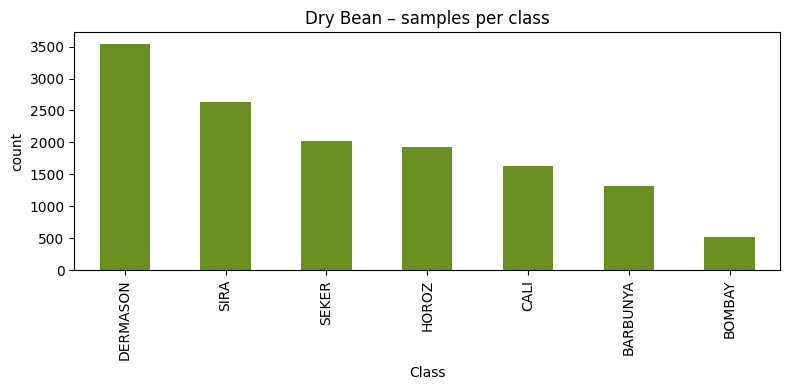

In [16]:
import matplotlib.pyplot as plt

ax = class_counts.plot(kind="bar", color="#6b8e23", figsize=(8, 4))
ax.set_title("Dry Bean – samples per class")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

## 1.4 Feature correlation
Many of the 16 shape features are derived from each other (Area, ConvexArea, Perimeter, EquivDiameter …), so strong correlation is expected. This matters for Naive Bayes, which assumes independent features.

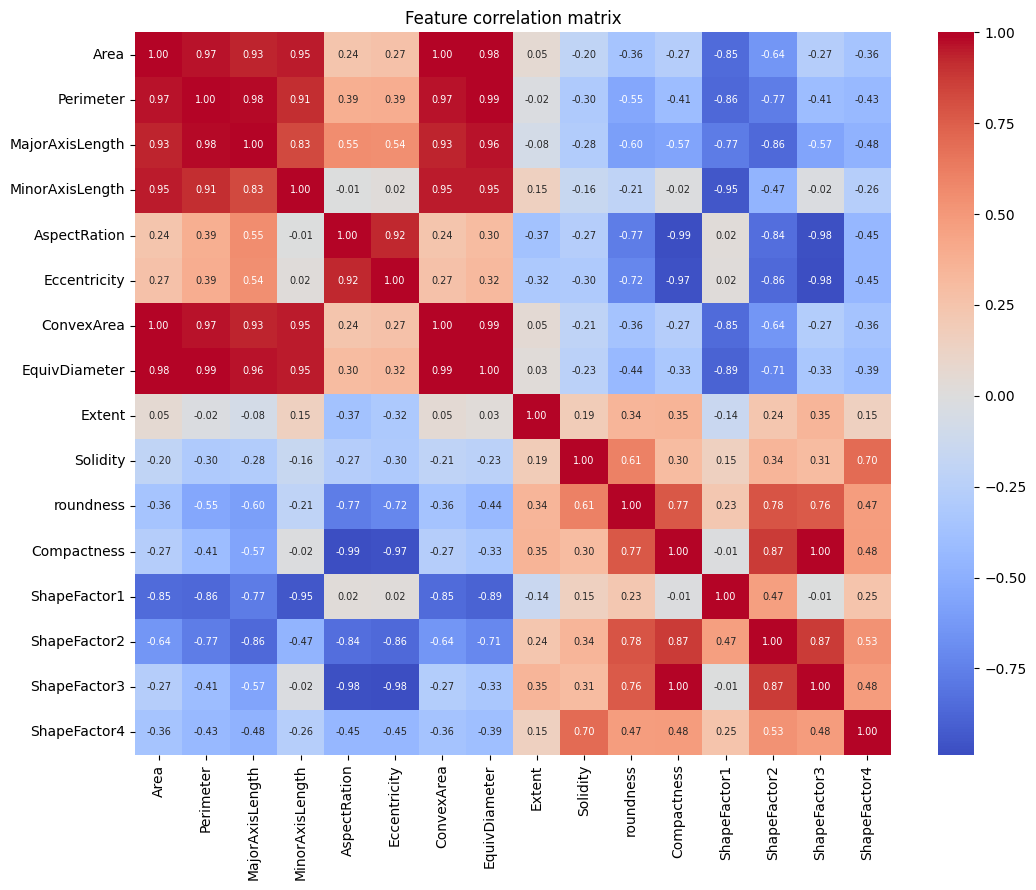

15 feature pairs with |r| > 0.95


[('Area', 'Perimeter', np.float64(0.967)),
 ('Area', 'MinorAxisLength', np.float64(0.952)),
 ('Area', 'ConvexArea', np.float64(1.0)),
 ('Area', 'EquivDiameter', np.float64(0.985)),
 ('Perimeter', 'MajorAxisLength', np.float64(0.977)),
 ('Perimeter', 'ConvexArea', np.float64(0.968)),
 ('Perimeter', 'EquivDiameter', np.float64(0.991)),
 ('MajorAxisLength', 'EquivDiameter', np.float64(0.962)),
 ('MinorAxisLength', 'ConvexArea', np.float64(0.951)),
 ('AspectRation', 'Compactness', np.float64(-0.988)),
 ('AspectRation', 'ShapeFactor3', np.float64(-0.979)),
 ('Eccentricity', 'Compactness', np.float64(-0.97)),
 ('Eccentricity', 'ShapeFactor3', np.float64(-0.981)),
 ('ConvexArea', 'EquivDiameter', np.float64(0.985)),
 ('Compactness', 'ShapeFactor3', np.float64(0.999))]

In [17]:
import seaborn as sns

corr = beans.drop(columns="Class").corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

strong = [(a, b, round(corr.loc[a, b], 3))
          for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
          if abs(corr.loc[a, b]) > 0.95]
print(f"{len(strong)} feature pairs with |r| > 0.95")
strong

## 1.5 Key findings
*(Write these in your own words after looking at the output above.)*

- 13,611 beans, 16 numeric shape features, 7 classes → multi-class problem.
- No missing values; a small number of exact duplicate rows.
- Classes are imbalanced (DERMASON largest, BOMBAY smallest) → use a stratified split and report macro-averaged metrics.
- Features are on very different scales (Area in tens of thousands vs ShapeFactor2 ≈ 0.002) → scaling needed for LR, KNN and SVM.
- Several features are almost perfectly correlated → likely to hurt Gaussian Naive Bayes.